# 02 — data cleaning

California Housing has no missing values, so this notebook focuses on outlier detection and understanding which columns are problematic.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.data_loader import load_california

sns.set_theme(style='whitegrid')
df = load_california()
print(df.shape)

(20640, 9)


## outlier detection — boxplots

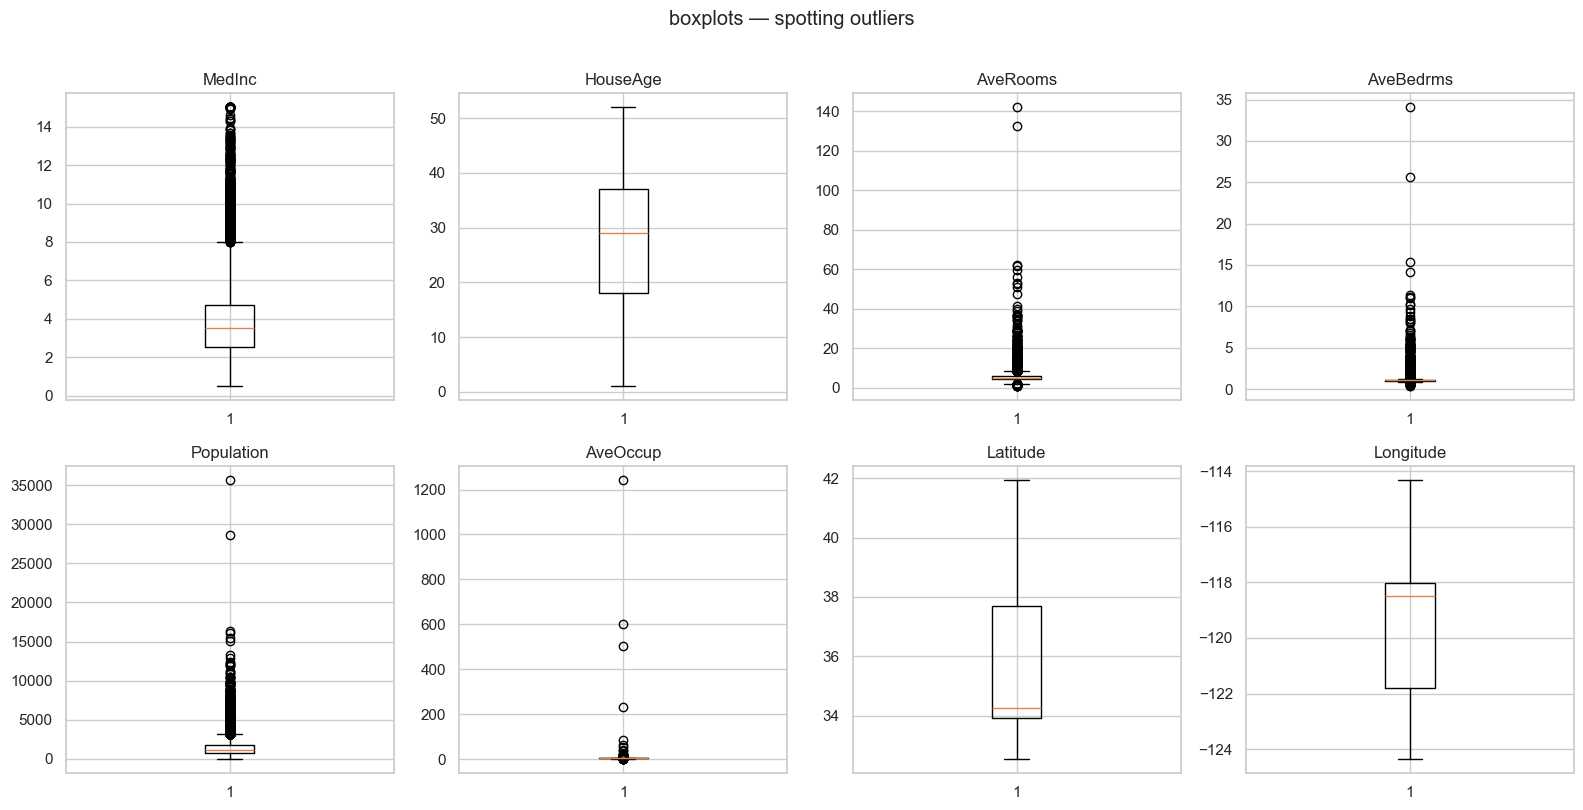

In [2]:
features = [c for c in df.columns if c != 'price']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    axes[i].boxplot(df[col], vert=True)
    axes[i].set_title(col)

plt.suptitle('boxplots — spotting outliers', y=1.01)
plt.tight_layout()
plt.savefig('../plots/boxplots.png', dpi=120)
plt.show()

`AveRooms`, `AveBedrms`, `Population`, and `AveOccup` all have extreme outliers. these are likely data errors or unusual blocks.

## check skewness

In [3]:
skewness = df.apply(lambda x: x.skew()).sort_values(ascending=False)
print(skewness.round(3))

AveOccup      97.640
AveBedrms     31.317
AveRooms      20.698
Population     4.936
MedInc         1.647
price          0.978
Latitude       0.466
HouseAge       0.060
Longitude     -0.298
dtype: float64


anything above ~0.75 is worth log-transforming. we'll handle this in notebook 03.

## cap extreme outliers in AveRooms and AveOccup

In [4]:
# check how many rows have unrealistic values
print("AveRooms > 50:", (df['AveRooms'] > 50).sum())
print("AveOccup > 10:", (df['AveOccup'] > 10).sum())
print("AveBedrms > 10:", (df['AveBedrms'] > 10).sum())
print("Population > 10000:", (df['Population'] > 10000).sum())

AveRooms > 50: 9
AveOccup > 10: 37
AveBedrms > 10: 9
Population > 10000: 23


In [5]:
# cap at 99th percentile to reduce outlier influence without dropping rows
cols_to_cap = ['AveRooms', 'AveBedrms', 'Population', 'AveOccup']

df_clean = df.copy()
for col in cols_to_cap:
    cap = df_clean[col].quantile(0.99)
    df_clean[col] = df_clean[col].clip(upper=cap)

print("rows removed: 0 (we capped, not dropped)")
print(df_clean.shape)

rows removed: 0 (we capped, not dropped)
(20640, 9)


## price cap at 5.0

rows with price == 5.0: 27


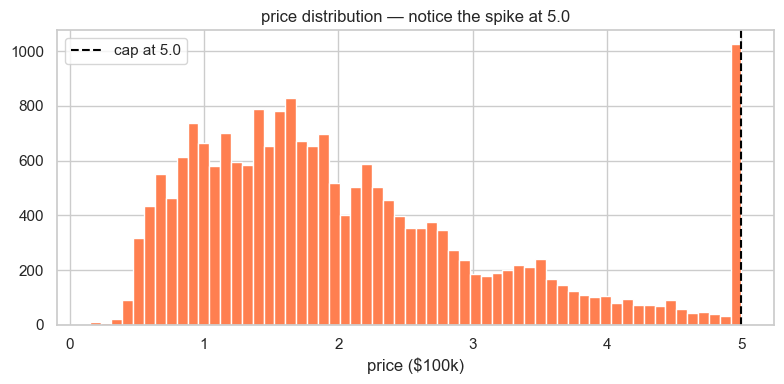

In [6]:
# the dataset clips prices at 5.0 ($500k) — a known quirk of this dataset
print("rows with price == 5.0:", (df_clean['price'] == 5.0).sum())

# visualize
plt.figure(figsize=(8, 4))
plt.hist(df_clean['price'], bins=60, color='coral', edgecolor='white')
plt.axvline(5.0, color='black', linestyle='--', label='cap at 5.0')
plt.xlabel('price ($100k)')
plt.legend()
plt.title('price distribution — notice the spike at 5.0')
plt.tight_layout()
plt.savefig('../plots/price_cap.png', dpi=120)
plt.show()

we'll keep these rows but it's worth knowing the model will struggle at the top end of prices.

## save cleaned data

In [7]:
df_clean.to_csv('../data/processed/california_clean.csv', index=False)
print("saved to data/processed/california_clean.csv")
df_clean.head()

saved to data/processed/california_clean.csv


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
